# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:** Sneha Kanjwani
- **Student ID:** 023-24-0273
- **Section:** H
- **GitHub:** https://github.com/snehakanjwani30/Machine-Learning-Labs
- **Kaggle:** https://www.kaggle.com/snehakanjwani
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [61]:
# YOUR CODE HERE
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.metrics import adjusted_rand_score

SEED = 42

print("All libraries imported successfully!")
print("SEED =", SEED)

All libraries imported successfully!
SEED = 42


### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [62]:
# YOUR CODE HERE
df = pd.read_csv("Mall_Customers.csv")
df = df.rename(columns={
    "Annual Income (k$)": "Income",
    "Spending Score (1-100)": "Spending"
})

print("Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())
print("\nGender Counts:")
print(df["Gender"].value_counts())
print("\nDescriptive Statistics:")
display(df[["Age", "Income", "Spending"]].describe())

Dataset Shape: (200, 5)

Missing Values:
CustomerID    0
Gender        0
Age           0
Income        0
Spending      0
dtype: int64

Duplicate Rows: 0

Gender Counts:
Gender
Female    112
Male       88
Name: count, dtype: int64

Descriptive Statistics:


,Age,Income,Spending
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


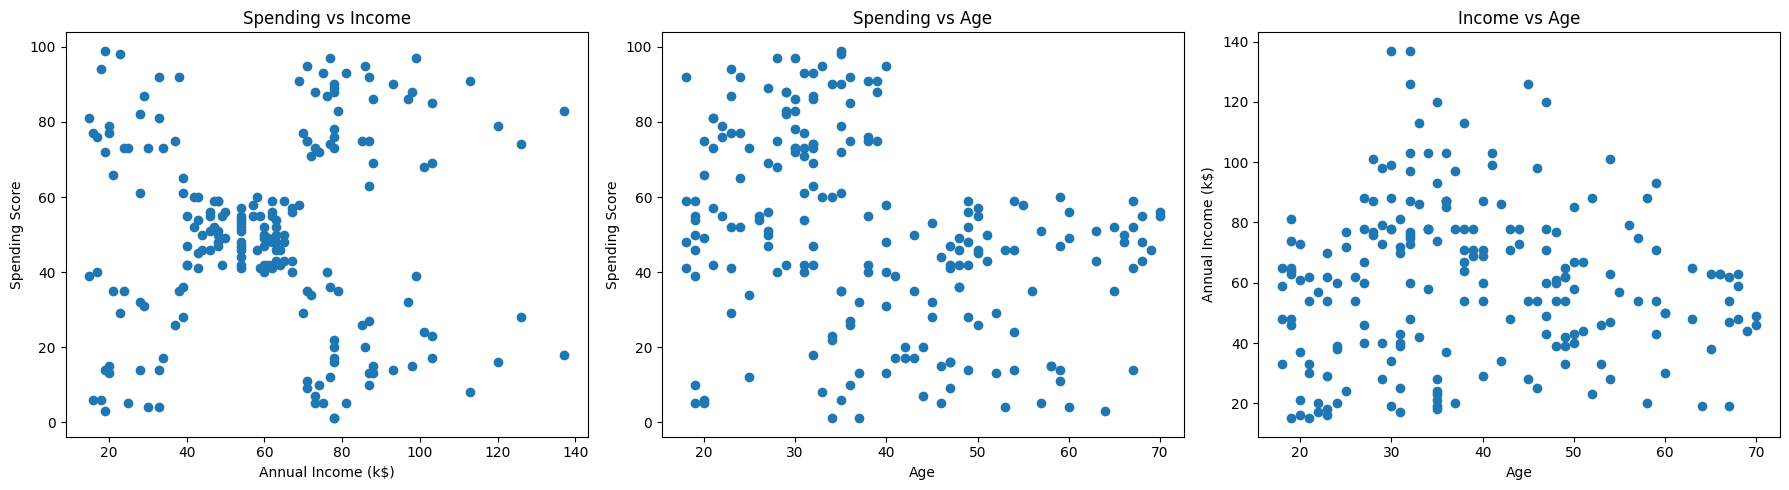

In [63]:
# YOUR CODE HERE
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(df["Income"], df["Spending"])
axes[0].set_title("Spending vs Income")
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Spending Score")

axes[1].scatter(df["Age"], df["Spending"])
axes[1].set_title("Spending vs Age")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Spending Score")

axes[2].scatter(df["Age"], df["Income"])
axes[2].set_title("Income vs Age")
axes[2].set_xlabel("Age")
axes[2].set_ylabel("Annual Income (k$)")

plt.tight_layout()
plt.show()

# Interpretation

Spending vs Income shows the clearest structure, with about 5 groups: low income/low spending, low income/high spending, a large middle group, high income/high spending and high income/low spending. Spending vs Age shows some patterns (young customers tend to have higher spending) but with much overlap. Income vs Age is scattered with no clear groups. So Income and Spending are the best pair for K-Means.

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



**Your answers:**

(a) The Spending vs Income plot shows approximately 5 visible groups and presents the clearest separation between customers. The Spending vs Age plot shows around 3 broad patterns, while the Income vs Age plot shows less distinct groups with considerable overlap.

(b) We cannot use accuracy because the dataset has no true cluster labels or target column. K-Means discovers groups from the data, rather than predicting known answers.


---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [64]:
# YOUR CODE HERE
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)

m = np.array([4.0, 11.0])

iteration = 1

while True:
    dist = np.abs(x[:, None] - m[None, :])

    labels = dist.argmin(axis=1)

    new_m = np.array([
        x[labels == k].mean() for k in range(2)
    ])

    print(f"\nIteration {iteration}")

    for k in range(2):
        print(f"Cluster {k + 1}:", x[labels == k].astype(int))

    print("New centroids:", new_m)

    if np.allclose(new_m, m):
        m = new_m
        break

    m = new_m
    iteration += 1

final_dist = np.abs(x - m[labels]) ** 2
inertia = final_dist.sum()

print("\nFinal centroids:", m)
print("Final inertia:", inertia)
print("Total iterations:", iteration)


Iteration 1
Cluster 1: [2 4 3]
Cluster 2: [10 12 20 30 11 25]
New centroids: [ 3. 18.]

Iteration 2
Cluster 1: [ 2  4 10  3]
Cluster 2: [12 20 30 11 25]
New centroids: [ 4.75 19.6 ]

Iteration 3
Cluster 1: [ 2  4 10 12  3 11]
Cluster 2: [20 30 25]
New centroids: [ 7. 25.]

Iteration 4
Cluster 1: [ 2  4 10 12  3 11]
Cluster 2: [20 30 25]
New centroids: [ 7. 25.]

Final centroids: [ 7. 25.]
Final inertia: 150.0
Total iterations: 4


# Interpretation

The final clusters are {2, 3, 4, 10, 11, 12} with centroid 7 and {20, 25, 30} with centroid 25, and the inertia is 150. This matches the lecture slides. Iteration 4 only confirmed that nothing changed.

### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [65]:
# YOUR CODE HERE
X = np.array([
    [185, 72],  # P1
    [170, 56],  # P2
    [168, 60],  # P3
    [179, 68],  # P4
    [182, 72],  # P5
    [188, 77]   # P6
], dtype=float)

point_names = ["P1", "P2", "P3", "P4", "P5", "P6"]

C = X[[0, 1]].copy()

iteration = 1

while True:
    distances = np.linalg.norm(X[:, None, :] - C[None, :, :], axis=2)

    labels = distances.argmin(axis=1)

    new_C = np.array([
        X[labels == k].mean(axis=0) if np.any(labels == k) else C[k]
        for k in range(2)
    ])

    print(f"\nIteration {iteration}")

    for k in range(2):
        cluster_points = [
            point_names[i] for i in range(len(X)) if labels[i] == k
        ]
        print(f"Cluster {k + 1}: {cluster_points}")

    print("Updated centroids:")
    print(new_C)

    if np.allclose(new_C, C):
        C = new_C
        break

    C = new_C
    iteration += 1

first_C = X[[0, 1]].copy()
first_distances = np.linalg.norm(
    X[:, None, :] - first_C[None, :, :], axis=2
)

print("\nFirst iteration distance check:")
print("d(P3, M2) =", round(first_distances[2, 1], 2))

final_distances = np.linalg.norm(
    X[:, None, :] - C[None, :, :], axis=2
)

distance_table = pd.DataFrame(
    final_distances,
    columns=["Distance to C1", "Distance to C2"],
    index=point_names
)

print("\nFinal distance table:")
display(distance_table.round(2))

print("Final centroids:")
print(C)


Iteration 1
Cluster 1: ['P1', 'P4', 'P5', 'P6']
Cluster 2: ['P2', 'P3']
Updated centroids:
[[183.5   72.25]
 [169.    58.  ]]

Iteration 2
Cluster 1: ['P1', 'P4', 'P5', 'P6']
Cluster 2: ['P2', 'P3']
Updated centroids:
[[183.5   72.25]
 [169.    58.  ]]

First iteration distance check:
d(P3, M2) = 4.47

Final distance table:


,Distance to C1,Distance to C2
P1,1.52,21.26
P2,21.13,2.24
P3,19.76,2.24
P4,6.19,14.14
P5,1.52,19.10
P6,6.54,26.87


Final centroids:
[[183.5   72.25]
 [169.    58.  ]]


# Interpretation

The loop converged with two clusters: {P1, P4, P5, P6} with centroid (183.5, 72.25) and {P2, P3} with centroid (169, 58). The first-iteration distance d(P3, M2) = 4.47 matches the lecture slide. In the final table every point is closer to its own centroid (for example P4: 6.19 to C1 vs 14.14 to C2), which confirms the assignment.

### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [66]:
# YOUR CODE HERE

def my_kmeans(X, init_centroids, max_iter=100):
    X = np.asarray(X, dtype=float)
    centroids = np.asarray(init_centroids, dtype=float).copy()

    for iteration in range(1, max_iter + 1):
        distances = np.linalg.norm(
            X[:, None, :] - centroids[None, :, :],
            axis=2
        )
        labels = distances.argmin(axis=1)
        new_centroids = centroids.copy()

        for k in range(len(centroids)):
            if np.any(labels == k):
                new_centroids[k] = X[labels == k].mean(axis=0)

        converged = np.allclose(new_centroids, centroids)
        centroids = new_centroids

        if converged:
            break

    distances = np.linalg.norm(
        X[:, None, :] - centroids[None, :, :],
        axis=2
    )
    labels = distances.argmin(axis=1)
    inertia = np.sum(
        (X - centroids[labels]) ** 2
    )

    return labels, centroids, inertia, iteration

In [67]:
# YOUR CODE HERE

# Example 1 test

x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
X_test = x.reshape(-1, 1)
initial_centroids = np.array([[4.0], [11.0]])

labels, centroids, inertia, iterations = my_kmeans(
    X_test,
    initial_centroids
)

print("Cluster 1:", X_test[labels == 0].flatten().astype(int))
print("Cluster 2:", X_test[labels == 1].flatten().astype(int))
print("Final centroids:", centroids.flatten())
print("Inertia:", inertia)
print("Iterations:", iterations)
print("\nCentroids match:", np.allclose(centroids.flatten(), [7, 25]))
print("Inertia matches:", np.isclose(inertia, 150))

Cluster 1: [ 2  4 10 12  3 11]
Cluster 2: [20 30 25]
Final centroids: [ 7. 25.]
Inertia: 150.0
Iterations: 4

Centroids match: True
Inertia matches: True


# Interpretation

my_kmeans gives centroids 7 and 25 and inertia 150 on Example 1, the same as the lecture and the loop in Task 1.1. Both match checks print True.

### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [68]:
# YOUR CODE HERE
X2 = df[["Income", "Spending"]].values

init_centroids = X2[:5].copy()

my_labels, my_centroids, my_inertia, my_iterations = my_kmeans(
    X2,
    init_centroids,
    max_iter=100
)

sk_model = KMeans(
    n_clusters=5,
    init=init_centroids,
    n_init=1,
    tol=0,
    algorithm="lloyd",
    random_state=SEED
)

sk_labels = sk_model.fit_predict(X2)

print("----- My K-Means -----")
print("Iterations:", my_iterations)
print("Inertia:", my_inertia)
print("Centroids:\n", my_centroids)

print("\n----- Scikit-learn K-Means -----")
print("Iterations:", sk_model.n_iter_)
print("Inertia:", sk_model.inertia_)
print("Centroids:\n", sk_model.cluster_centers_)

print("\n----- Comparison -----")
print("Same inertia:", np.isclose(my_inertia, sk_model.inertia_))
print("Same labels:", np.array_equal(my_labels, sk_labels))
print(
    "Same centroids:",
    np.allclose(my_centroids, sk_model.cluster_centers_)
)

# Compare cluster labels row by row
label_comparison = pd.DataFrame({
    "CustomerID": df["CustomerID"],
    "My_KMeans_Label": my_labels,
    "Sklearn_Label": sk_labels,
    "Labels_Match": my_labels == sk_labels
})
display(label_comparison.head(10))
centroid_comparison = pd.DataFrame({
    "My_Income": my_centroids[:, 0],
    "My_Spending": my_centroids[:, 1],
    "Sklearn_Income": sk_model.cluster_centers_[:, 0],
    "Sklearn_Spending": sk_model.cluster_centers_[:, 1]
})

display(centroid_comparison.round(2))

----- My K-Means -----
Iterations: 4
Inertia: 44448.45544793371
Centroids:
 [[26.30434783 20.91304348]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [86.53846154 82.12820513]
 [55.2962963  49.51851852]]

----- Scikit-learn K-Means -----
Iterations: 4
Inertia: 44448.45544793371
Centroids:
 [[26.30434783 20.91304348]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [86.53846154 82.12820513]
 [55.2962963  49.51851852]]

----- Comparison -----
Same inertia: True
Same labels: True
Same centroids: True


,CustomerID,My_KMeans_Label,Sklearn_Label,Labels_Match
0,1,0,0,True
1,2,1,1,True
2,3,0,0,True
3,4,1,1,True
4,5,0,0,True
5,6,1,1,True
6,7,0,0,True
7,8,1,1,True
8,9,0,0,True
9,10,1,1,True


,My_Income,My_Spending,Sklearn_Income,Sklearn_Spending
0,26.30,20.91,26.30,20.91
1,25.73,79.36,25.73,79.36
2,88.20,17.11,88.20,17.11
3,86.54,82.13,86.54,82.13
4,55.30,49.52,55.30,49.52


# Interpretation


My K-Means implementation and scikit-learn's KMeans produced identical results using the same initial centroids. Both algorithms converged in 4 iterations and achieved an inertia of 44448.4554. The cluster labels and centroid coordinates also matched exactly. This confirms that my implementation correctly performs distance calculation, cluster assignment, centroid updates, and convergence checking for this dataset.

**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



**Your answers:**

(a) In iteration 1, the centroids were 4 and 11. The point 10 was closer to centroid 11, so it was assigned to cluster C2. After the centroids were updated, the centroid of C1 became 3 and the centroid of C2 became 18. The distance of 10 from centroid 3 was 7, while its distance from centroid 18 was 8. Therefore, in iteration 2, point 10 moved to C1 because it was now closer to C1.

(b) The loop stops when the centroids no longer change, checked using np.allclose(new_centroids, centroids), or when the maximum iteration limit is reached. The algorithm normally converges because each assignment and centroid update reduces or maintains the within-cluster sum of squared distances. However, convergence does not guarantee the globally best clustering because the result can depend on the initial centroids.

(c) Yes, my function matched scikit-learn exactly. Both algorithms converged in 4 iterations, produced an inertia of 44448.4554, and returned identical cluster labels and centroid coordinates. This confirms that my implementation performed correctly for the given dataset and initialization.

(d) A centroid represents the average feature values of customers in a cluster. For example, a centroid with Income 26.30 and Spending 20.91 represents a group whose average annual income is approximately $26.30 thousand and whose average spending score is 20.91. K-Means requires numeric features because it calculates distances and means mathematically; categorical features such as Gender must be encoded numerically before being used.


---

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


,K,Inertia,Silhouette
0,2,181363.5960,0.2969
1,3,106348.3731,0.4676
2,4,73679.7890,0.4932
3,5,44448.4554,0.5539
4,6,37233.8145,0.5398
5,7,30241.3436,0.5288
6,8,25036.4176,0.4548
7,9,21916.7948,0.4561
8,10,20072.0709,0.4411


K with the highest silhouette score: 5


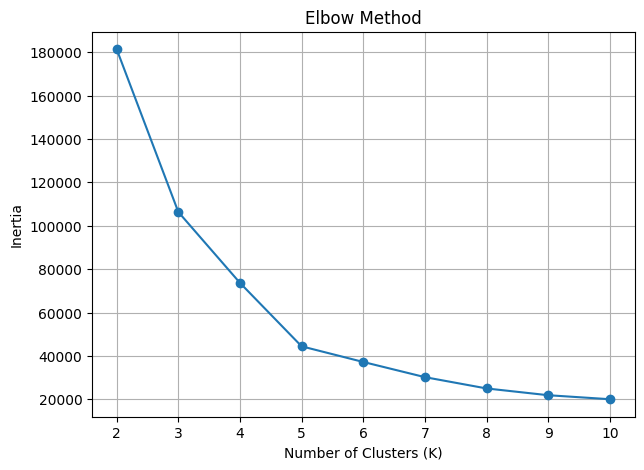

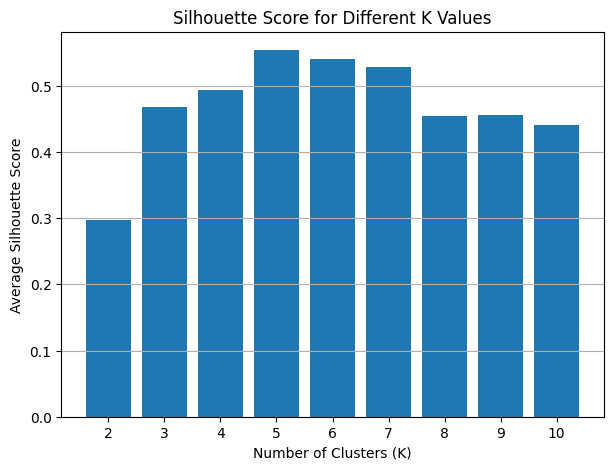

In [69]:
# YOUR CODE HERE
results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=SEED
    )

    labels = model.fit_predict(X2)

    inertia = model.inertia_
    silhouette = silhouette_score(X2, labels)

    results.append({
        "K": k,
        "Inertia": inertia,
        "Silhouette": silhouette
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

best_k = results_df.loc[
    results_df["Silhouette"].idxmax(), "K"
]

print("K with the highest silhouette score:", int(best_k))

plt.figure(figsize=(7, 5))
plt.plot(
    results_df["K"],
    results_df["Inertia"],
    marker="o"
)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 5))
plt.bar(
    results_df["K"],
    results_df["Silhouette"]
)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Average Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.xticks(range(2, 11))
plt.grid(axis="y")
plt.show()

# Interpretation 

Inertia decreases as K increases, from 181363.5960 at K = 2 to 20072.0709 at K = 10. This is expected because increasing the number of clusters generally reduces within-cluster distances. The silhouette score reaches its maximum of 0.5539 at K = 5, indicating that five clusters provide the best separation among the tested values according to this metric. Therefore, K = 5 is a strong choice for customer segmentation, supported by the silhouette score and the elbow curve.

### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


In [70]:
# YOUR CODE HERE
kmeans_5 = KMeans(n_clusters=5, n_init=10, random_state=SEED)
labels_5 = kmeans_5.fit_predict(X2)
sil_values = silhouette_samples(X2, labels_5)

def manual_silhouette(X, labels, point_index):
    X = np.asarray(X, dtype=float)
    labels = np.asarray(labels)

    distances = np.sqrt(((X - X[point_index]) ** 2).sum(axis=1))
    own_cluster = labels[point_index]

    same = labels == own_cluster
    same[point_index] = False

    if not same.any():
        return 0.0, np.nan, 0.0

    a = distances[same].mean()

    other_means = [
        distances[labels == c].mean()
        for c in np.unique(labels)
        if c != own_cluster
    ]
    b = min(other_means)

    s = (b - a) / max(a, b) if max(a, b) > 0 else 0.0
    return a, b, s

a, b, s = manual_silhouette(X2, labels_5, 0)

print("Customer 1 (row 0)")
print("Cluster:", labels_5[0])
print(f"Manual a: {a:.6f}")
print(f"Manual b: {b:.6f}")
print(f"Manual silhouette: {s:.6f}")
print(f"sklearn silhouette: {sil_values[0]:.6f}")
print(f"Difference: {abs(s - sil_values[0]):.10f}")

summary = pd.DataFrame({
    "Cluster": labels_5,
    "Silhouette": sil_values
}).groupby("Cluster")["Silhouette"].agg(
    Count="count",
    Mean="mean",
    Minimum="min"
).round(4)

print("\nSilhouette summary by cluster:")
display(summary)

negative_count = int((sil_values < 0).sum())
print("Customers with negative silhouette:", negative_count)
print("Overall mean silhouette:", round(sil_values.mean(), 4))

weakest = summary["Mean"].idxmin()
print(
    f"Weakest cluster by mean silhouette: {weakest} "
    f"(mean = {summary.loc[weakest, 'Mean']:.4f})"
)


Customer 1 (row 0)
Cluster: 4
Manual a: 24.640442
Manual b: 42.265267
Manual silhouette: 0.417005
sklearn silhouette: 0.417005
Difference: 0.0000000000

Silhouette summary by cluster:


,Count,Mean,Minimum
Cluster,,,
0,81,0.5967,0.1153
1,39,0.5092,0.2254
2,22,0.5990,0.0507
3,35,0.5040,-0.0234
4,23,0.5123,-0.0093


Customers with negative silhouette: 2
Overall mean silhouette: 0.5539
Weakest cluster by mean silhouette: 3 (mean = 0.5040)


# Interpretation

Customer 1 belongs to Cluster 4 and has a silhouette score of 0.4170. Since the score is positive, the customer is closer to its own cluster than to the nearest alternative cluster. The manual calculation matches the sklearn result exactly, confirming that the calculation is correct. The cluster summary shows that Cluster 2 has the highest mean silhouette score (0.5990), indicating the best average cluster separation, while Cluster 3 has the lowest mean score (0.5040). Two customers have negative silhouette scores, suggesting that they may be assigned to less suitable clusters. The overall mean silhouette score is 0.5539, indicating reasonably good separation among the five clusters, although some customers may not fit their assigned clusters well.

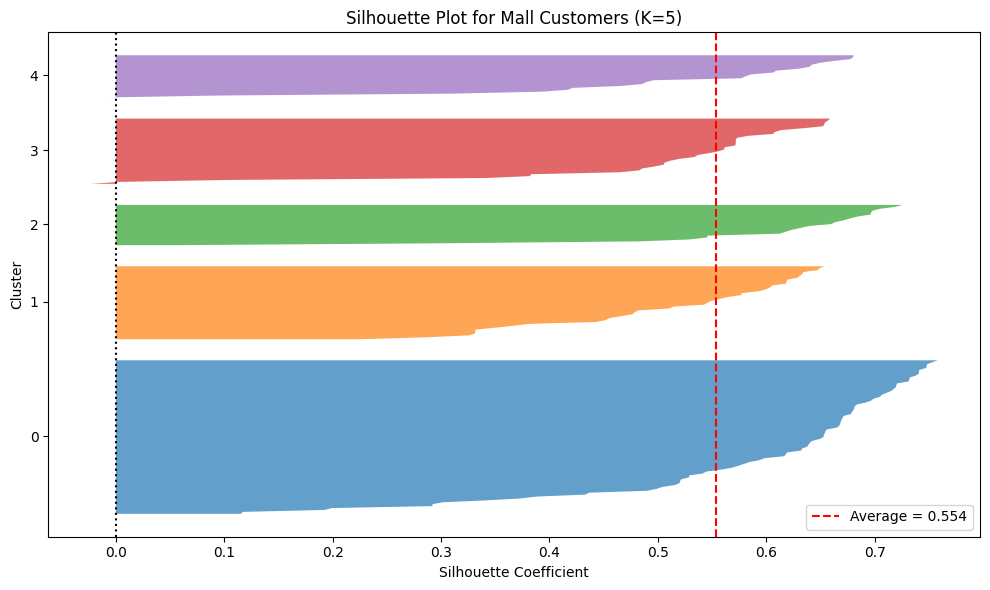

Interpretation: The average silhouette is 0.5539. Mostly positive values indicate better-separated clusters; values near or below zero indicate weaker assignments.


In [71]:
# YOUR CODE HERE
fig, ax = plt.subplots(figsize=(10, 6))
y_lower = 10
cluster_centers = []

for c in sorted(np.unique(labels_5)):
    values = np.sort(sil_values[labels_5 == c])
    y_upper = y_lower + len(values)

    ax.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        values,
        alpha=0.7
    )

    cluster_centers.append((y_lower + y_upper) / 2)
    y_lower = y_upper + 10

ax.axvline(
    sil_values.mean(),
    color="red",
    linestyle="--",
    label=f"Average = {sil_values.mean():.3f}"
)
ax.axvline(0, color="black", linestyle=":")

ax.set_title("Silhouette Plot for Mall Customers (K=5)")
ax.set_xlabel("Silhouette Coefficient")
ax.set_ylabel("Cluster")
ax.set_yticks(cluster_centers)
ax.set_yticklabels(sorted(np.unique(labels_5)))
ax.legend()
plt.tight_layout()
plt.show()

print(
    f"Interpretation: The average silhouette is {sil_values.mean():.4f}. "
    "Mostly positive values indicate better-separated clusters; "
    "values near or below zero indicate weaker assignments."
)

### Task 2.3 — The lecture practice problem

Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).

1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes for your own revision.


In [72]:
# YOUR CODE HERE
X_practice = np.array([1, 3, 5, 7, 11, 13, 15], dtype=float).reshape(-1, 1)
initial_centroids = np.array([[1.0], [11.0]])

labels_practice, centroids_practice, inertia_practice, iterations_practice = my_kmeans(
    X_practice, initial_centroids.copy()
)

print("Final Clusters:")
for c in range(2):
    print(f"Cluster {c}: {X_practice[labels_practice == c].ravel().astype(int)}")

print("\nFinal Centroids:", centroids_practice.ravel())
print("Inertia:", inertia_practice)
print("Iterations:", iterations_practice)

sil_practice = silhouette_samples(X_practice, labels_practice)

results = []

for point in [1, 7, 11]:
    index = int(np.where(X_practice.ravel() == point)[0][0])

    a, b, s = manual_silhouette(
        X_practice, labels_practice, index
    )

    results.append({
        "Point": point,
        "Cluster": labels_practice[index],
        "a (Own Cluster)": a,
        "b (Nearest Other Cluster)": b,
        "Manual Silhouette": s,
        "sklearn Silhouette": sil_practice[index]
    })

results_df = pd.DataFrame(results).round(4)

print("\nManual vs sklearn Silhouette:")
display(results_df)


Final Clusters:
Cluster 0: [1 3 5 7]
Cluster 1: [11 13 15]

Final Centroids: [ 4. 13.]
Inertia: 28.0
Iterations: 3

Manual vs sklearn Silhouette:


,Point,Cluster,a (Own Cluster),b (Nearest Other Cluster),Manual Silhouette,sklearn Silhouette
0,1,0,4.0,12.0,0.6667,0.6667
1,7,0,4.0,6.0,0.3333,0.3333
2,11,1,3.0,7.0,0.5714,0.5714


# Interpretation


The K-Means algorithm divides the seven points into two clusters: Cluster 0 = {1, 3, 5, 7} and Cluster 1 = {11, 13, 15}. The final centroids are 4 and 13, respectively, and the final inertia is 28.0. The algorithm converges after 3 iterations. The silhouette calculations show that Point 1 is better separated from the other cluster, with a score of 0.6667, compared with Point 7's score of 0.3333. Both points have the same average distance to their own cluster (\(a=4\)), but Point 7 has a smaller average distance to the nearest other cluster (\(b=6\)), making its cluster assignment less distinct. Point 11 has a silhouette score of 0.5714, indicating reasonably good placement in Cluster 1.
Finally, the manual silhouette scores match the sklearn scores for all three points, confirming that the manual calculations are correct.

**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

(d) Why should we never choose K only by the lowest inertia?



**Your answers:**

(a) The elbow suggests K = 5. The inertia falls by 75,015 from K=2 to 3 and by 32,669 from K=3 to 4. It then falls by 29,231 from K=4 to 5, but by only 7,215 from K=5 to 6 and 6,992 from K=6 to 7. The curve bends after K = 5, because adding more clusters gives little extra gain. The silhouette is highest at K = 5 (0.5539), compared with 0.4932 at K=4 and 0.5398 at K=6. The two methods agree on K = 5.

(b) Customer 1 has a silhouette score of 0.4170, with \(a = 24.6404\) and \(b = 42.2653\). This means Customer 1 is reasonably well placed in Cluster 4 because its average distance to its own cluster is smaller than its average distance to the nearest other cluster.
Cluster 3 has the weakest mean silhouette score of 0.5040. There are 2 customers with negative silhouette scores, indicating that these customers may be closer on average to another cluster than to their assigned cluster. The overall mean silhouette score is 0.5539, indicating reasonably good cluster separation overall.

(c) Point 7 is less well placed. Both points have the same average distance to their own cluster, \(a = 4\). However, Point 7 has \(b = 6\), while Point 1 has \(b = 12\). Therefore, Point 7 is closer to the other cluster and has a lower silhouette score of 0.3333, compared with Point 1's score of 0.6667.

(d) We should not choose K only by the lowest inertia because inertia generally decreases as the number of clusters increases. With too many clusters, inertia can become very small, but the segmentation may no longer be useful. Instead, we should consider the elbow method, silhouette scores, and whether the resulting clusters are meaningful and useful for the task.


---

## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


Best inertia across all runs: 44448.4554


,Setting,Distinct Inertias (1 d.p.),Lowest Inertia,Highest Inertia,Runs Reaching Best (%)
0,"random, n_init=1",14,44448.5,91762.0,33.3
1,"k-means++, n_init=1",6,44448.5,66733.4,60.0
2,"k-means++, n_init=10",1,44448.5,44448.5,100.0


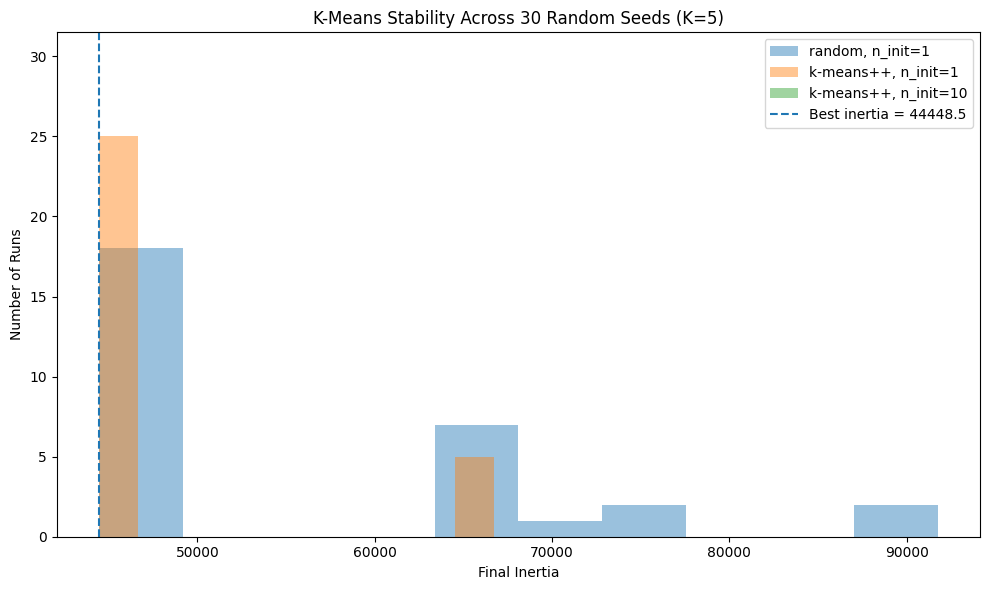

In [73]:
# YOUR CODE HERE
K = 5
seeds = range(30)

settings = [
    ("random, n_init=1", "random", 1),
    ("k-means++, n_init=1", "k-means++", 1),
    ("k-means++, n_init=10", "k-means++", 10)
]

results = []

for setting_name, init_method, n_init_value in settings:
    for seed in seeds:
        model = KMeans(
            n_clusters=K,
            init=init_method,
            n_init=n_init_value,
            random_state=seed
        )

        model.fit(X2)

        results.append({
            "Setting": setting_name,
            "Seed": seed,
            "Inertia": model.inertia_
        })

results_df = pd.DataFrame(results)

best_inertia = results_df["Inertia"].min()
best_inertia_rounded = round(best_inertia, 1)

summary = []

for setting_name, _, _ in settings:
    group = results_df[results_df["Setting"] == setting_name]
    rounded_inertia = group["Inertia"].round(1)

    summary.append({
        "Setting": setting_name,
        "Distinct Inertias (1 d.p.)": rounded_inertia.nunique(),
        "Lowest Inertia": group["Inertia"].min(),
        "Highest Inertia": group["Inertia"].max(),
        "Runs Reaching Best (%)": (
            rounded_inertia == best_inertia_rounded
        ).mean() * 100
    })

summary_df = pd.DataFrame(summary)
summary_df["Lowest Inertia"] = summary_df["Lowest Inertia"].round(1)
summary_df["Highest Inertia"] = summary_df["Highest Inertia"].round(1)
summary_df["Runs Reaching Best (%)"] = (
    summary_df["Runs Reaching Best (%)"].round(1)
)

print(f"Best inertia across all runs: {best_inertia:.4f}")
display(summary_df)

plt.figure(figsize=(10, 6))

for setting_name, _, _ in settings:
    values = results_df.loc[
        results_df["Setting"] == setting_name, "Inertia"
    ]
    plt.hist(values, bins=10, alpha=0.45, label=setting_name)

plt.axvline(
    best_inertia,
    linestyle="--",
    label=f"Best inertia = {best_inertia:.1f}"
)

plt.xlabel("Final Inertia")
plt.ylabel("Number of Runs")
plt.title("K-Means Stability Across 30 Random Seeds (K=5)")
plt.legend()
plt.tight_layout()
plt.show()

# Interpretation


Random, n_init=1 shows the greatest variation, with 14 distinct inertia values. k-means++, n_init=1 is more consistent, with 60% of runs reaching the best inertia. k-means++, n_init=10 performs best, with all 30 runs achieving the lowest inertia of 44,448.5, demonstrating the benefit of multiple initializations.

### Task 3.2 — Best run vs worst run

See what a bad local minimum looks like.

1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by side.
2. Print their inertia and their ARI.


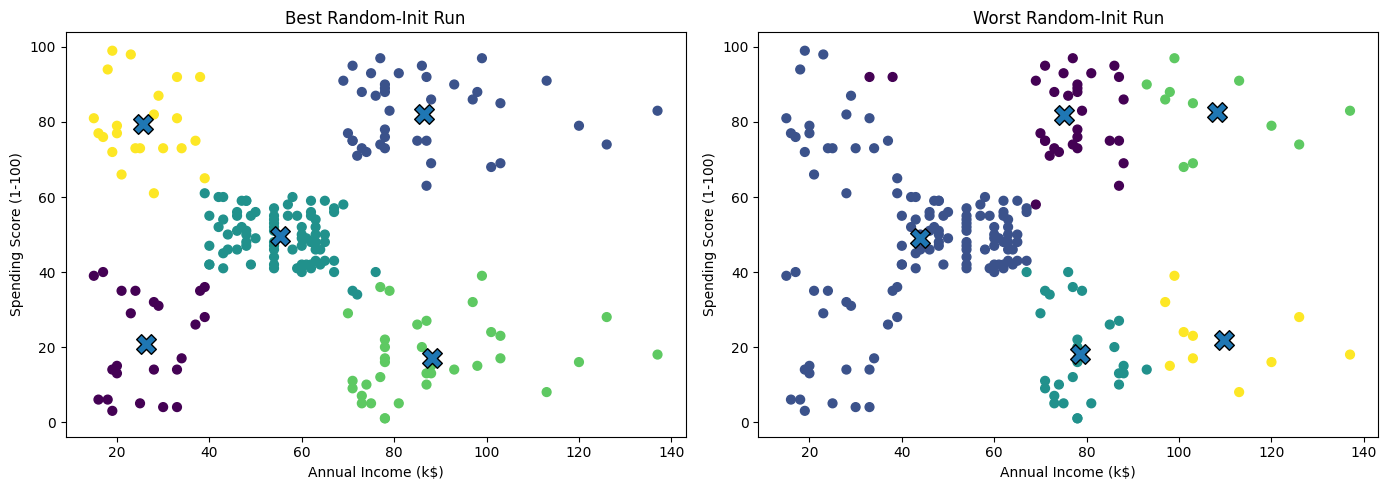

Best run seed: 0
Best run inertia: 44448.4554
Worst run seed: 13
Worst run inertia: 91761.9762
Adjusted Rand Index (ARI): 0.4553


In [74]:
# YOUR CODE HERE
random_results = results_df[
    results_df["Setting"] == "random, n_init=1"
]

best_seed = random_results.loc[random_results["Inertia"].idxmin(), "Seed"]
worst_seed = random_results.loc[random_results["Inertia"].idxmax(), "Seed"]

best_model = KMeans(
    n_clusters=5, init="random", n_init=1, random_state=int(best_seed)
).fit(X2)

worst_model = KMeans(
    n_clusters=5, init="random", n_init=1, random_state=int(worst_seed)
).fit(X2)

ari = adjusted_rand_score(best_model.labels_, worst_model.labels_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model, title in [
    (axes[0], best_model, "Best Random-Init Run"),
    (axes[1], worst_model, "Worst Random-Init Run")
]:
    ax.scatter(
    X2[:, 0], X2[:, 1],
    c=model.labels_, cmap="viridis", s=40
    )
    ax.scatter(
        model.cluster_centers_[:, 0],
        model.cluster_centers_[:, 1],
        marker="X", s=200, edgecolor="black"
    )
    ax.set_title(title)
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score (1-100)")

plt.tight_layout()
plt.show()

print(f"Best run seed: {best_seed}")
print(f"Best run inertia: {best_model.inertia_:.4f}")
print(f"Worst run seed: {worst_seed}")
print(f"Worst run inertia: {worst_model.inertia_:.4f}")
print(f"Adjusted Rand Index (ARI): {ari:.4f}")

# Interpretation


The best random-init run (seed 0) reached inertia 44,448.5, which is the best solution found in all settings. The worst run (seed 13) got stuck in a local minimum with inertia 91,762.0, about twice as high. Their ARI is only 0.4553, so the two runs split the customers into quite different groups. In the worst plot, the starting points put two centroids close together and left a real group without its own centroid. This is why a single random start is risky and why k-means++ and n_init=10 are used.

**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?



**Your answers:**

(a) The random-start setting produced 14 distinct inertia values, and 33.3% of its runs reached the best inertia. With k-means++ and n_init=1, there were 6 distinct values and 60% reached the best. With k-means++ and n_init=10, there was only 1 distinct value, and 100% of runs reached the best inertia.

(b) The same data and K can give different results because K-Means starts with different initial centroids. These starting points can lead the algorithm to different local minima.

(c) K-means++ chooses better-spread initial centroids, while n_init runs K-Means multiple times and keeps the result with the lowest inertia. In my experiment, n_init=10 achieved the best inertia of 44,448.5 in all 30 runs.

(d) We use ARI because cluster numbers are arbitrary. For example, Cluster 0 in one run may represent the same group as Cluster 3 in another. ARI compares the actual groupings rather than their label numbers.


---

## Part 4 — Scaling: Units Decide the Clusters (25 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it twice: once by only changing the unit of Income, and once on the Wine data where the features have very different sizes and the true groups are known.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| External check | Comparing clusters with known true groups. Possible only for teaching data like Wine. Real clustering problems have no labels. | `adjusted_rand_score(y_true, labels)` |
| PCA (Lab 8) | Reduces many features to 2 so we can draw the data. Used here only for the plot. | `PCA(n_components=2)` |


### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10, random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.


Raw k$ vs Raw dollars: ARI = 0.4897
Scaled k$ vs Scaled dollars: ARI = 1.0000
Raw dollars vs Scaled dollars: ARI = 0.3605


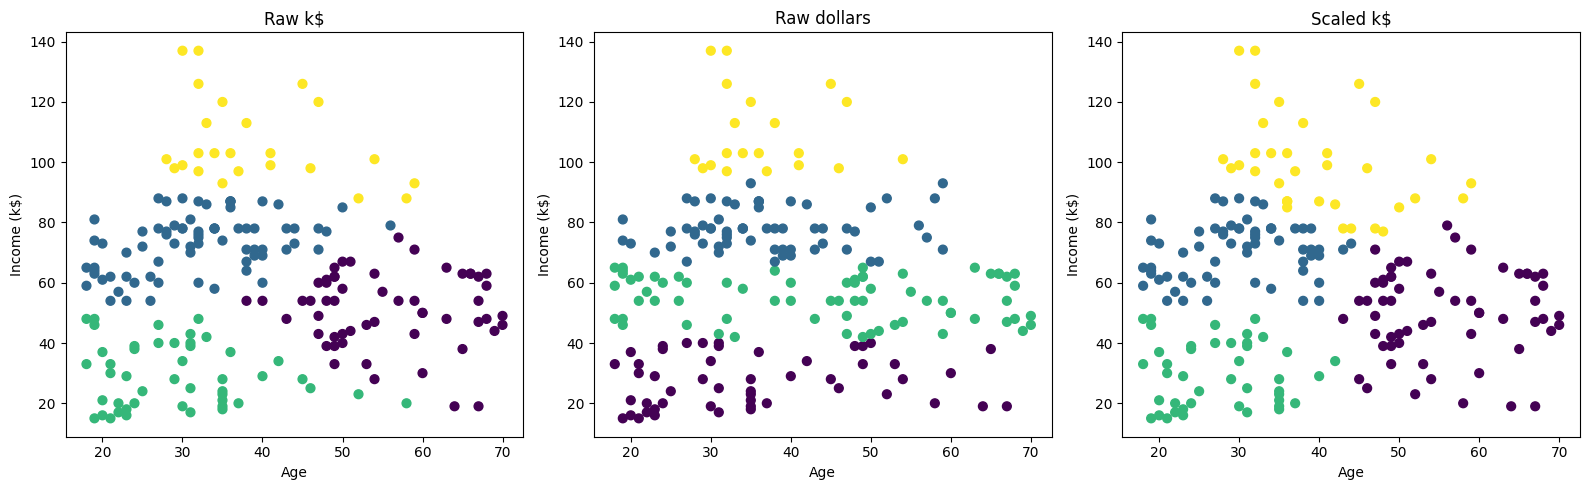

In [75]:
# YOUR CODE HERE
X_age_income = df[["Age", "Income"]].copy()

X_dollars = X_age_income.copy()
X_dollars["Income"] = X_dollars["Income"] * 1000

X_scaled_k = StandardScaler().fit_transform(X_age_income)
X_scaled_dollars = StandardScaler().fit_transform(X_dollars)

models = {
    "Raw k$": KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_age_income),
    "Raw dollars": KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_dollars),
    "Scaled k$": KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_scaled_k),
    "Scaled dollars": KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_scaled_dollars)
}

comparisons = [
    ("Raw k$ vs Raw dollars", "Raw k$", "Raw dollars"),
    ("Scaled k$ vs Scaled dollars", "Scaled k$", "Scaled dollars"),
    ("Raw dollars vs Scaled dollars", "Raw dollars", "Scaled dollars")
]

for name, first, second in comparisons:
    ari = adjusted_rand_score(
        models[first].labels_,
        models[second].labels_
    )
    print(f"{name}: ARI = {ari:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

plot_settings = [
    ("Raw k$", models["Raw k$"].labels_),
    ("Raw dollars", models["Raw dollars"].labels_),
    ("Scaled k$", models["Scaled k$"].labels_)
]

for ax, (title, labels) in zip(axes, plot_settings):
    ax.scatter(
        X_age_income["Age"],
        X_age_income["Income"],
        c=labels,
        cmap="viridis",
        s=40
    )
    ax.set_title(title)
    ax.set_xlabel("Age")
    ax.set_ylabel("Income (k$)")

plt.tight_layout()
plt.show()

# Interpretation

Changing Income from thousands to dollars changes the raw clusters, giving an ARI of 0.4897. After scaling, both versions produce identical clusters (ARI = 1.0000). The raw-dollars versus scaled-dollars ARI is 0.3605, showing that scaling significantly changes the clustering results.

### Task 4.2 — Wine data: raw vs scaled

Load the Wine data with load_wine(): 178 wines, 13 chemical measurements, 3 true grape cultivars. The true cultivar is used ONLY to check the result, never to fit K-Means.

1. Print the three largest and the smallest standard deviation of the features.
2. Run KMeans(K=3, n_init=10, random_state=SEED) on the raw data and on the scaled data. For each report ARI against the true cultivar, silhouette score and cluster sizes.


In [76]:
# YOUR CODE HERE
wine = load_wine()
X_wine = pd.DataFrame(wine.data, columns=wine.feature_names)
y_wine = wine.target  

std_values = X_wine.std().sort_values(ascending=False)

print("Three largest feature standard deviations:")
display(std_values.head(3).to_frame("Standard Deviation").round(4))

print("Smallest feature standard deviation:")
display(std_values.tail(1).to_frame("Standard Deviation").round(4))

scaler = StandardScaler()
X_wine_scaled = scaler.fit_transform(X_wine)

print("Raw data shape:", X_wine.shape)
print("Number of true cultivars:", len(set(y_wine)))

Three largest feature standard deviations:


,Standard Deviation
proline,314.9075
magnesium,14.2825
alcalinity_of_ash,3.3396


Smallest feature standard deviation:


,Standard Deviation
nonflavanoid_phenols,0.1245


Raw data shape: (178, 13)
Number of true cultivars: 3


# Interpretation 


The Wine dataset contains 178 samples and 13 features. The feature standard deviations vary, showing that the chemical measurements have different numerical scales. Features with larger scales can dominate distance calculations, which is why scaling is important before applying K-Means.

In [77]:
# YOUR CODE HERE
kmeans_raw = KMeans(
    n_clusters=3, n_init=10, random_state=SEED
)
labels_raw = kmeans_raw.fit_predict(X_wine)

kmeans_scaled = KMeans(
    n_clusters=3, n_init=10, random_state=SEED
)
labels_scaled = kmeans_scaled.fit_predict(X_wine_scaled)

results = []

for name, X, labels in [
    ("Raw", X_wine, labels_raw),
    ("Scaled", X_wine_scaled, labels_scaled)
]:
    results.append({
        "Data": name,
        "ARI": adjusted_rand_score(y_wine, labels),
        "Silhouette": silhouette_score(X, labels),
        "Cluster Sizes": sorted(
            pd.Series(labels).value_counts().tolist(),
            reverse=True
        )
    })

results_df = pd.DataFrame(results).round(4)
display(results_df)

,Data,ARI,Silhouette,Cluster Sizes
0,Raw,0.3711,0.5711,"[69, 62, 47]"
1,Scaled,0.8975,0.2849,"[65, 62, 51]"


# Interpretation

On the raw data, K-Means gave ARI = 0.3711, silhouette = 0.5711 and cluster sizes [69, 62, 47]. On the scaled data it gave ARI = 0.8975, silhouette = 0.2849 and sizes [65, 62, 51]. Scaling raised the agreement with the true cultivars from 0.37 to 0.90, and the scaled cluster sizes are much closer to the real group sizes. The raw silhouette is higher only because Proline dominates the distance, so it does not show a better clustering.

### Task 4.3 — Draw it

Compare the three views in one picture.

1. Use one PCA of the scaled data and draw three plots with the same axes: true cultivars, raw clusters, scaled clusters.


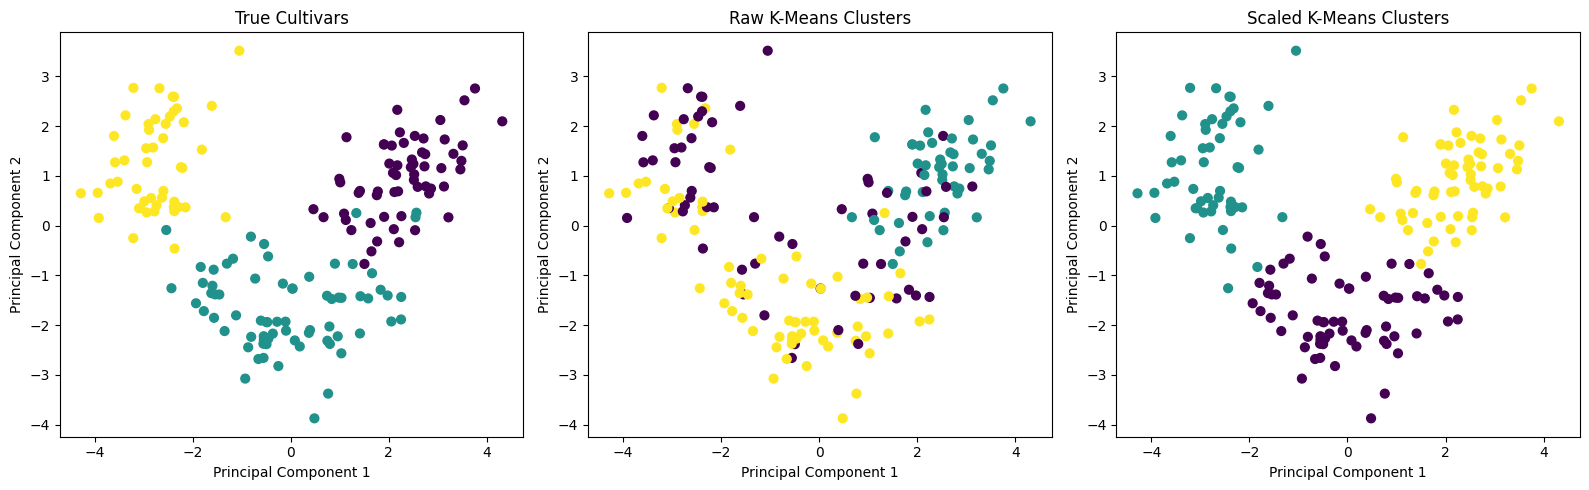

Variance explained by the two PCA components: 55.41 %


In [78]:
# YOUR CODE HERE
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_wine_scaled)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

plots = [
    ("True Cultivars", y_wine),
    ("Raw K-Means Clusters", labels_raw),
    ("Scaled K-Means Clusters", labels_scaled)
]

for ax, (title, labels) in zip(axes, plots):
    ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap="viridis",
        s=40
    )
    ax.set_title(title)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

print(
    "Variance explained by the two PCA components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# Interpretation


The first two principal components explain 55.41% of the total variance in the scaled Wine data. This means the 2D PCA plots preserve about 55.41% of the dataset's variation, allowing us to visually compare the true cultivars with the raw and scaled K-Means clusters. The remaining 44.59% of the variance is not shown in these two dimensions.

**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).

(b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared with the others? What were the ARI values raw vs scaled?

(c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette can mislead here and why comparing it between raw and scaled data is not fair.

(d) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.



**Your answers:**

(a) Changing Income from thousands to dollars changed the raw clusters (ARI = 0.4897). Since Euclidean distance squares feature differences, Income in dollars dominates the distance because its values become 1,000 times larger. After scaling, both versions produced identical clusters (ARI = 1.0000).

(b) On the raw Wine data, Proline dominated the distance. Its standard deviation is 314.9, about 22 times that of magnesium (14.3, the next largest) and about 2,500 times that of nonflavanoid phenols (0.12, the smallest). Because Euclidean distance squares differences, the raw clusters were decided almost only by Proline. The ARI against the true cultivars was 0.3711 on the raw data and 0.8975 on the scaled data, so scaling improved agreement with the real cultivars a lot.

(c) The raw Wine clustering had a higher silhouette (0.5711) than the scaled one (0.2849), even though its ARI was much worse (0.3711 vs 0.8975). Silhouette only measures how compact and separated the clusters are under the distance being used. On raw data that distance is almost one-dimensional (Proline), so splitting the data along Proline gives tidy, well-separated groups that do not match the real cultivars. Raw and scaled silhouettes are also not comparable, because they are measured in different distance spaces: raw units vs standardized units with 13 features all contributing.

(d)I would scale features when their units or numerical ranges differ significantly and I want each feature to contribute comparably to distance. I would consider leaving them unscaled when their original scales intentionally represent their relative importance.


---

## Part 5 — Outliers and Anomalies (20 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and then catch it with a distance rule (the anomaly detection idea from the lecture).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |
| Anomaly detection | Using the clusters to find strange points (far from every centroid). | `Sort by the distance column.` |


### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original 200 customers.
3. Draw the two clusterings side by side.


In [80]:
# YOUR CODE HERE
X2_outlier = np.vstack([X2, [400, 99]])

kmeans_original = KMeans(
    n_clusters=5, n_init=10, random_state=SEED
)
labels_original = kmeans_original.fit_predict(X2)

kmeans_outlier = KMeans(
    n_clusters=5, n_init=10, random_state=SEED
)
labels_outlier = kmeans_outlier.fit_predict(X2_outlier)

print("Cluster sizes WITHOUT outlier:")
print(pd.Series(labels_original).value_counts().sort_index())

print("\nCluster sizes WITH outlier:")
print(pd.Series(labels_outlier).value_counts().sort_index())

centroids_original = kmeans_original.cluster_centers_
centroids_with_outlier = kmeans_outlier.cluster_centers_

print("\nCentroids WITHOUT outlier (sorted by Income):")
print(pd.DataFrame(
    centroids_original,
    columns=["Income", "Spending"]
).sort_values("Income").round(2).to_string(index=False))

print("\nCentroids WITH outlier (sorted by Income):")
print(pd.DataFrame(
    centroids_with_outlier,
    columns=["Income", "Spending"]
).sort_values("Income").round(2).to_string(index=False))

ari = adjusted_rand_score(
    labels_original,
    labels_outlier[:len(X2)]
)
print(f"\nARI on original 200 customers: {ari:.4f}")

Cluster sizes WITHOUT outlier:
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Cluster sizes WITH outlier:
0    100
1      1
2     23
3     39
4     38
Name: count, dtype: int64

Centroids WITHOUT outlier (sorted by Income):
 Income  Spending
  25.73     79.36
  26.30     20.91
  55.30     49.52
  86.54     82.13
  88.20     17.11

Centroids WITH outlier (sorted by Income):
 Income  Spending
  26.30     20.91
  48.26     56.48
  86.54     82.13
  87.00     18.63
 400.00     99.00

ARI on original 200 customers: 0.7532


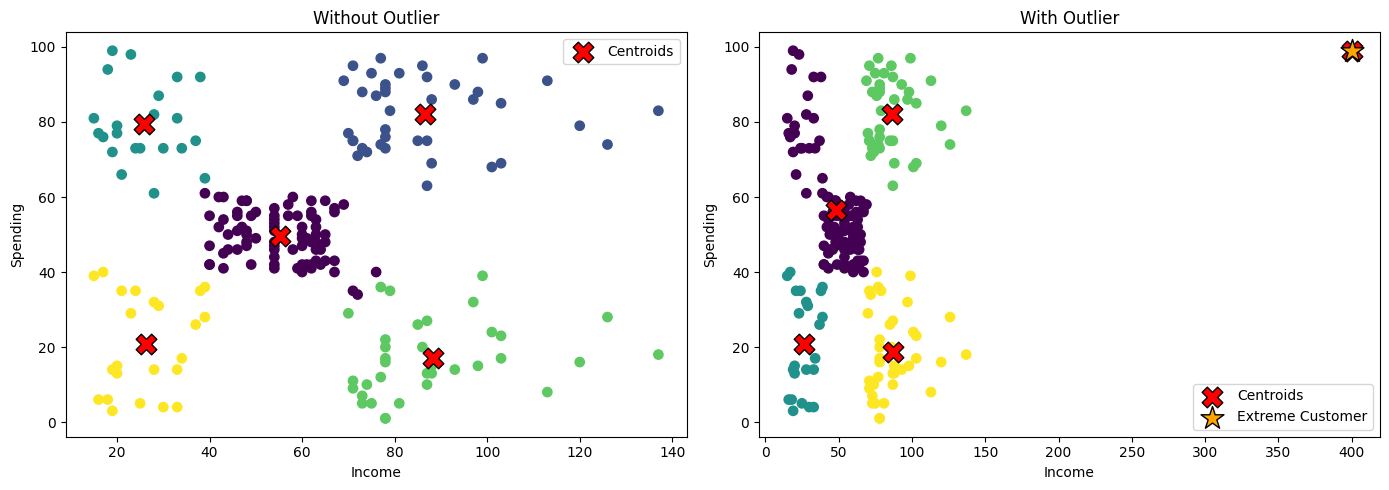

In [81]:
# YOUR CODE HERE
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    X2[:, 0], X2[:, 1],
    c=labels_original, cmap="viridis", s=45
)
axes[0].scatter(
    centroids_original[:, 0], centroids_original[:, 1],
    marker="X", s=220, c="red", edgecolor="black",
    label="Centroids"
)
axes[0].set_title("Without Outlier")
axes[0].set_xlabel("Income")
axes[0].set_ylabel("Spending")
axes[0].legend()

axes[1].scatter(
    X2_outlier[:, 0], X2_outlier[:, 1],
    c=labels_outlier, cmap="viridis", s=45
)
axes[1].scatter(
    centroids_with_outlier[:, 0],
    centroids_with_outlier[:, 1],
    marker="X", s=220, c="red", edgecolor="black",
    label="Centroids"
)
axes[1].scatter(
    400, 99, marker="*", s=300, c="orange",
    edgecolor="black", label="Extreme Customer"
)
axes[1].set_title("With Outlier")
axes[1].set_xlabel("Income")
axes[1].set_ylabel("Spending")
axes[1].legend()

plt.tight_layout()
plt.show()

# Interpretation


Adding the extreme customer (400, 99) changed the cluster sizes and centroids significantly. One cluster contains only the outlier, and the ARI of 0.7532 shows that the clustering of the original 200 customers changed. The outlier pulled one centroid far away from the main customer groups, demonstrating that K-Means is sensitive to extreme values.

### Task 5.2 — Catch it and repair

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are flagged? Is the extra customer flagged?
3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster, Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on the 200 customers (use predict).


In [82]:
# YOUR CODE HERE
distances_real = kmeans_original.transform(X2).min(axis=1)

extra_customer = np.array([[400, 99]])
extra_distance = kmeans_original.transform(extra_customer).min(axis=1)[0]

distance_mean = distances_real.mean()
distance_std = distances_real.std()
threshold = distance_mean + 3 * distance_std

flagged_mask = distances_real > threshold
flagged_indices = np.where(flagged_mask)[0]

print(f"Mean distance: {distance_mean:.4f}")
print(f"Standard deviation: {distance_std:.4f}")
print(f"Threshold (mean + 3 std): {threshold:.4f}")
print(f"Real customers flagged: {flagged_mask.sum()}")
print(f"Extra customer distance: {extra_distance:.4f}")
print(f"Is extra customer flagged? {extra_distance > threshold}")
if "CustomerID" in df.columns:
    customer_ids = df["CustomerID"].to_numpy()
else:
    customer_ids = np.arange(1, len(X2) + 1)

if "Age" in df.columns:
    ages = df["Age"].to_numpy()
else:
    ages = np.full(len(X2), np.nan)

farthest_df = pd.DataFrame({
    "CustomerID": customer_ids[:len(X2)],
    "Age": ages[:len(X2)],
    "Income": X2[:, 0],
    "Spending": X2[:, 1],
    "Cluster": labels_original,
    "Distance": distances_real
})

print("\nFive real customers farthest from their centroid:")
print(
    farthest_df.nlargest(5, "Distance")
    .round(4)
    .to_string(index=False)
)

X2_clean = X2[~flagged_mask]

kmeans_clean = KMeans(
    n_clusters=5,
    n_init=10,
    random_state=SEED
)
labels_clean = kmeans_clean.fit_predict(X2_clean)

print("\nCluster sizes after removing flagged customers:")
print(pd.Series(labels_clean).value_counts().sort_index())

labels_clean_all = kmeans_clean.predict(X2)

ari_repaired = adjusted_rand_score(
    labels_original,
    labels_clean_all
)
print(f"\nARI vs original model on all 200 customers: {ari_repaired:.4f}")

Mean distance: 13.0201
Standard deviation: 7.2608
Threshold (mean + 3 std): 34.8024
Real customers flagged: 4
Extra customer distance: 313.9153
Is extra customer flagged? True

Five real customers farthest from their centroid:
 CustomerID  Age  Income  Spending  Cluster  Distance
        200   30     137        83        1   50.4691
        199   32     137        18        3   48.8080
        198   32     126        74        1   40.2900
        197   45     126        28        3   39.3362
        196   35     120        79        1   33.6074

Cluster sizes after removing flagged customers:
0    80
1    34
2    23
3    37
4    22
Name: count, dtype: int64

ARI vs original model on all 200 customers: 0.9847


# Interpretation


The mean + 3 standard deviations threshold is 34.8024. Four real customers were flagged, while the extra customer's distance of 313.9153 was far above the threshold, so it was correctly detected as an outlier. After removing the four flagged real customers and refitting K-Means, the ARI was 0.9847, indicating that the repaired clustering is very similar to the original clustering.

**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.

(c) Name two ways to deal with outliers and one risk of simply deleting them.



**Your answers:**

(a) Without the outlier the cluster sizes were 81, 39, 22, 35, 23. With the outlier they became 100, 1, 23, 39, 38. The outlier took a whole cluster for itself (centroid 400, 99). That left only four centroids for the 200 real customers, so two real groups were merged: Low Income/High Spending (centroid 25.73, 79.36) and Mid/Mid (55.30, 49.52) became one cluster of 100 with centroid (48.26, 56.48). The High Income/Low Spending centroid also shifted from (88.20, 17.11) to (87.00, 18.63) as its cluster grew from 35 to 38. The Low Income/Low Spending cluster (26.30, 20.91, size 23) and the High/High cluster (86.54, 82.13, size 39) did not change. ARI = 0.7532.

(b) The rule worked well: the threshold was 34.8024, while the extra customer's distance was 313.9153, so it was correctly flagged. The rule also flagged 4 real customers. Their incomes were 137, 137, 126, and 126, with Spending Scores of 83, 18, 74, and 28. These customers have relatively high incomes compared with many other customers, so they may be unusual observations worth investigating rather than automatically treating them as incorrect data.

(c) Two ways to handle outliers: (1) detect them with a distance rule such as mean + 3 std and remove them once they are confirmed to be errors; (2) cap (winsorize) extreme values, or use a method that is robust to outliers such as K-Medoids or DBSCAN, which labels outliers as noise. Risk of deleting them: a rare but real group (for example, very high-income VIP customers) is lost, so the clustering no longer represents all customers.

---

## Part 6 — From Clusters to Customer Segments (25 minutes)

Clusters are numbers (0, 1, 2 ...). The business needs names and actions. Cluster numbers are arbitrary labels: cluster 3 in one run has no meaning by itself. Use the original 200 customers and K = 5 on Income and Spending (random_state=SEED).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Cluster profile | The average of every feature inside each cluster, plus the cluster size. This is how you read what a cluster means. | `df.groupby('Cluster').agg(...)` |
| Segment | A cluster with a name and an action, for example 'High income / Low spending'. | `df['Cluster'].map(names)` |
| Crosstab | Counts or percentages of one category inside another (Gender inside Segment). | `pd.crosstab(a, b, normalize='index')` |


### Task 6.1 — Profile and name the segments

Make the clustering readable for a manager.

1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income, mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid; Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


In [83]:
# YOUR CODE HERE
df_clustered = df.copy()
df_clustered["Cluster"] = labels_original

gender_col = next(
    col for col in df_clustered.columns
    if col.lower() == "gender"
)

female_pct = (
    df_clustered.assign(
        Female=df_clustered[gender_col].astype(str).str.strip().str.lower()
        .eq("female").astype(int) * 100
    )
    .groupby("Cluster")["Female"]
    .mean()
)

profile = df_clustered.groupby("Cluster").agg(
    Customers=("Cluster", "size"),
    Mean_Age=("Age", "mean"),
    Mean_Income=("Income", "mean"),
    Mean_Spending=("Spending", "mean")
)

profile["Female_%"] = female_pct
profile = profile.sort_values("Mean_Income")

display(profile.round(2))

,Customers,Mean_Age,Mean_Income,Mean_Spending,Female_%
Cluster,,,,,
2,22,25.27,25.73,79.36,59.09
4,23,45.22,26.30,20.91,60.87
0,81,42.72,55.30,49.52,59.26
1,39,32.69,86.54,82.13,53.85
3,35,41.11,88.20,17.11,45.71


# Interpretation


Cluster 0 is the largest cluster, with 81 customers, and has mid-level average income (55.30) and spending (49.52). Cluster 1 has high average income (86.54) and high spending (82.13), while Cluster 3 has high income (88.20) but low spending (17.11). Clusters 2 and 4 have low average incomes, but Cluster 2 spends more on average (79.36) than Cluster 4 (20.91).

In [84]:
# YOUR CODE HERE
def income_level(value):
    if value < 40:
        return "Low"
    elif value >= 70:
        return "High"
    return "Mid"

def spending_level(value):
    if value < 35:
        return "Low"
    elif value >= 65:
        return "High"
    return "Mid"

segment_names = {}

for cluster, row in profile.iterrows():
    income = income_level(row["Mean_Income"])
    spending = spending_level(row["Mean_Spending"])
    segment_names[cluster] = f"{income} Income / {spending} Spending"

df_clustered["Segment"] = df_clustered["Cluster"].map(segment_names)

print("Segment names:")
for cluster, name in segment_names.items():
    print(f"Cluster {cluster}: {name}")

print("\nCustomer count per segment:")
display(
    df_clustered["Segment"]
    .value_counts()
    .rename_axis("Segment")
    .to_frame("Customers")
)

Segment names:
Cluster 2: Low Income / High Spending
Cluster 4: Low Income / Low Spending
Cluster 0: Mid Income / Mid Spending
Cluster 1: High Income / High Spending
Cluster 3: High Income / Low Spending

Customer count per segment:


,Customers
Segment,
Mid Income / Mid Spending,81
High Income / High Spending,39
High Income / Low Spending,35
Low Income / Low Spending,23
Low Income / High Spending,22


# Interpretation


The largest segment is Mid Income / Mid Spending, with 81 customers. The High Income / High Spending segment has 39 customers, followed by High Income / Low Spending with 35. The Low Income / Low Spending and Low Income / High Spending segments contain 23 and 22 customers, respectively. These segments help businesses design targeted marketing strategies for different customer groups.

### Task 6.2 — Does Gender matter? Does Age matter?

Gender and Age were not used in the clusters. Check whether they would add something.

1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


In [85]:
# YOUR CODE HERE
gender_col = next(
    col for col in df_clustered.columns
    if col.lower() == "gender"
)

df_clustered["Is_Female"] = (
    df_clustered[gender_col]
    .astype(str).str.strip().str.lower().eq("female")
)

print("Percentage of women in each segment:")
women_by_segment = (
    df_clustered.groupby("Segment")["Is_Female"]
    .mean().mul(100)
    .to_frame("Female_%")
)
display(women_by_segment.round(2))

overall_female_pct = df_clustered["Is_Female"].mean() * 100
print(f"Overall percentage of women: {overall_female_pct:.2f}%")

X_ais = df_clustered[["Age", "Income", "Spending"]]

scaler = StandardScaler()
X_ais_scaled = scaler.fit_transform(X_ais)

silhouette_results = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=SEED
    )
    labels = model.fit_predict(X_ais_scaled)

    silhouette_results.append({
        "K": k,
        "Silhouette": silhouette_score(X_ais_scaled, labels)
    })

silhouette_df = pd.DataFrame(silhouette_results)

print("\nAverage silhouette scores for K = 2 to 8:")
display(silhouette_df.round(4))

best_row = silhouette_df.loc[silhouette_df["Silhouette"].idxmax()]
print(
    f"Best K = {int(best_row['K'])}, "
    f"Silhouette = {best_row['Silhouette']:.4f}"
)

Percentage of women in each segment:


,Female_%
Segment,
High Income / High Spending,53.85
High Income / Low Spending,45.71
Low Income / High Spending,59.09
Low Income / Low Spending,60.87
Mid Income / Mid Spending,59.26


Overall percentage of women: 56.00%

Average silhouette scores for K = 2 to 8:


,K,Silhouette
0,2,0.3355
1,3,0.3578
2,4,0.4040
3,5,0.4166
4,6,0.4284
5,7,0.4172
6,8,0.4082


Best K = 6, Silhouette = 0.4284


# Interpretation 1 — Percentage of Women in Each Segment


The overall percentage of women is 56%. The Low Income / Low Spending segment has the highest percentage of women at 60.87%, while the High Income / Low Spending segment has the lowest at 45.71%. The percentages are relatively similar across segments, so Gender does not appear to strongly distinguish the customer groups.

# Interpretation 2 — Average Silhouette Scores


The highest silhouette score is 0.4284 at K = 6, indicating that six clusters give the best separation among the tested values of K = 2 to 8 when Age, Income, and Spending are scaled together. The score improves from 0.3355 at K = 2 to K = 6, then decreases for K = 7 and K = 8. This suggests that including Age may provide additional grouping information, although the silhouette score alone does not prove that six clusters are the most useful business choice.

### Task 6.3 — A three-feature alternative

Cluster the scaled Age, Income and Spending with the best K from the table above.

1. Fit it, build its profile table (size, Age, Income, Spending) sorted by Age.
2. Print the ARI between this segmentation and your 2-feature K = 5 segmentation.


In [86]:
# YOUR CODE HERE
kmeans_3feature = KMeans(
    n_clusters=6,
    n_init=10,
    random_state=SEED
)

labels_3feature = kmeans_3feature.fit_predict(X_ais_scaled)

df_3feature = df_clustered.copy()
df_3feature["Cluster_3Feature"] = labels_3feature

profile_3feature = df_3feature.groupby("Cluster_3Feature").agg(
    Customers=("Cluster_3Feature", "size"),
    Mean_Age=("Age", "mean"),
    Mean_Income=("Income", "mean"),
    Mean_Spending=("Spending", "mean")
).sort_values("Mean_Age")

print("Three-feature cluster profile (sorted by Age):")
display(profile_3feature.round(2))

ari_3feature = adjusted_rand_score(
    labels_original,
    labels_3feature
)

print(
    "ARI between 2-feature K=5 and 3-feature K=6: "
    f"{ari_3feature:.4f}"
)

Three-feature cluster profile (sorted by Age):


,Customers,Mean_Age,Mean_Income,Mean_Spending
Cluster_3Feature,,,,
4,23,25.00,25.26,77.61
1,39,26.79,57.10,48.13
3,39,32.69,86.54,82.13
2,33,41.94,88.94,16.97
5,21,45.52,26.29,19.38
0,45,56.33,54.27,49.07


ARI between 2-feature K=5 and 3-feature K=6: 0.7002


# Interpretation


The three-feature model with K = 6 creates six customer segments with different age and spending patterns. Cluster 0 has the highest mean age (56.33 years), while Cluster 4 has the lowest (25 years) and high average spending (77.61). The ARI of 0.7002 indicates considerable similarity, but also some differences, between the three-feature K = 6 and original two-feature K = 5 segmentations. Including Age changes how some customers are grouped.

**Questions** (answer with your own numbers)

(a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table.

(b) Which segment is the most valuable now and which one is the biggest opportunity? Why?

(c) Does Gender help to separate the segments? Quote the percentages.

(d) Does adding Age change the story? Which segmentation would you present and why? (Careful: silhouette values from different feature sets are not directly comparable.)



**Your answers:**

(a)
| Segment | Customers | Mean Income | Mean Spending | Business Name | Recommended Action |
|---|---:|---:|---:|---|---|
| Low Income / High Spending | 22 | 25.73 | 79.36 | Budget Enthusiasts | Offer loyalty points and affordable bundles to encourage repeat purchases. |
| Low Income / Low Spending | 23 | 26.30 | 20.91 | Budget-Conscious Customers | Send discounts on popular, low-cost products. |
| Mid Income / Mid Spending | 81 | 55.30 | 49.52 | Steady Customers | Offer personalized recommendations and seasonal promotions. |
| High Income / High Spending | 39 | 86.54 | 82.13 | Premium Customers | Provide VIP rewards, exclusive products, and early access to new collections. |
| High Income / Low Spending | 35 | 88.20 | 17.11 | Untapped Affluent Customers | Send targeted offers and premium product recommendations to encourage more spending. |

(b) The High Income / High Spending segment is the most valuable now because its 39 customers have high average Income (86.54) and Spending (82.13). They are already spending heavily, so loyalty rewards could help retain them.
The High Income / Low Spending segment is the biggest opportunity because its 35 customers have high average Income (88.20) but low Spending (17.11). Targeted offers may encourage them to spend more.

(c) Gender does not appear to strongly separate the segments. Overall, women represent 56.00% of customers. The percentage ranges from 45.71% in High Income / Low Spending to 60.87% in Low Income / Low Spending. The other segments are 53.85% women for High Income / High Spending, 59.09% for Low Income / High Spending, and 59.26% for Mid Income / Mid Spending. These differences are relatively small, so Gender is not a strong distinguishing feature here.

(d) Yes. The three-feature model (K = 6) separates customers partly by age. For example, Cluster 0 has the highest mean Age (56.33 years), while Cluster 4 has the lowest (25.00 years) and high mean Spending (77.61). The ARI between the original two-feature K = 5 and three-feature K = 6 segmentations is 0.7002, showing that some customer groupings change.
I would present the two-feature K = 5 segmentation as the main business model because Income and Spending directly support marketing and customer-value decisions, and the five segments are easy to explain. I would present the three-feature model as a secondary analysis if age-specific campaigns are important. The silhouette scores should not be compared directly across these models because they use different feature sets.


---

## Part 7 — Final Output and Wrap-Up (15 minutes)

Package your result like you would give it to a marketing team.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |


### Task 7.1 — Save the segments

Create a CSV with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.

1. Save it as customer_segments.csv and print the number of customers per segment.
2. Write a 6-8 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, one action per segment (short), how you handled scaling and outliers, and one limitation.


In [87]:
# YOUR CODE HERE
output_columns = [
    "CustomerID", "Age", "Gender", "Income",
    "Spending", "Cluster", "Segment"
]

customer_segments = df_clustered[output_columns].copy()

customer_segments.to_csv("customer_segments.csv", index=False)

print("File saved as customer_segments.csv")
print(f"Total customers: {len(customer_segments)}")

print("\nNumber of customers per segment:")
display(
    customer_segments["Segment"]
    .value_counts()
    .rename_axis("Segment")
    .to_frame("Customers")
)

File saved as customer_segments.csv
Total customers: 200

Number of customers per segment:


,Customers
Segment,
Mid Income / Mid Spending,81
High Income / High Spending,39
High Income / Low Spending,35
Low Income / Low Spending,23
Low Income / High Spending,22


# Interpretation


The CSV file was saved successfully and contains all 200 customers. The largest segment is Mid Income / Mid Spending with 81 customers, while the smallest is Low Income / High Spending with 22 customers. These five segments help identify different customer groups and plan suitable marketing strategies for each group.

**Executive Summary** (6-8 lines)

1. **Model Selection:** K-Means with K = 5 was selected using Income and Spending. It achieved the highest silhouette score of 0.5539 among K = 2 to 10.
2. **Customer Segments:** The five segments are Low Income / High Spending (22 customers), Low Income / Low Spending (23), Mid Income / Mid Spending (81), High Income / High Spending (39), and High Income / Low Spending (35).
3. **Marketing Actions:** Offer loyalty rewards to Low Income / High Spending customers, discounts to Low Income / Low Spending customers, and personalized promotions to Mid Income / Mid Spending customers.
4. **Premium Strategy:** Provide VIP benefits to High Income / High Spending customers and targeted premium offers to High Income / Low Spending customers.
5. **Scaling:** Income (std 26.3) and Spending (std 25.8) are on similar scales, so the final two-feature model was fitted without scaling. Part 4 shows that scaling is essential when units differ, and StandardScaler was used for the Age + Income + Spending model.
6. **Outlier Handling:** The mean + 3 standard deviations rule flagged four real customers. The extra extreme customer was also detected, and refitting after removing flagged real customers gave an ARI of 0.9847 against the original model.
7. **Limitation:** K-Means is sensitive to outliers and initial centroids, and the segments describe patterns in this dataset rather than proving future purchasing behavior.

**Questions** (answer with your own numbers)

(a) What was the most surprising result in this lab?

(b) If you had one more hour, what would you try next?



**Your answers:**

(a) The most surprising result was that adding just one extreme customer with Income = 400 and Spending = 99 changed the cluster sizes significantly and reduced the ARI to 0.7532. The mean + 3 standard deviations rule successfully detected the extra customer, and removing the four flagged real customers produced an ARI of 0.9847 against the original clustering.

(b) I would compare K-Means with and without feature scaling and test different values of K. I would also try another clustering algorithm, such as DBSCAN, which can identify outliers as noise. Finally, I would evaluate whether the resulting customer segments lead to useful, targeted marketing strategies.


---